In [2]:
#Bibliotecas
import geopandas as gpd
import pandas as pd
import numpy as np
from scipy import stats
caminho_base = r'C:\Users\Waxl_Sampaio\Documents\Artigo_previa\Escolas_Aponds'
caminho_ive = f"{caminho_base}\\Timon_Apond_IVE_4D_Final.gpkg"
caminho_escolas = f"{caminho_base}\\Escolas_por_Apond_Timon_Limpo_Final.gpkg"

# Carregar dados
gdf_ive = gpd.read_file(caminho_ive)
gdf_escolas = gpd.read_file(caminho_escolas)
# Merge das duas bases pelo código da AP
df_merged = pd.merge(
    gdf_ive[['cd_apond', 'IVE_FINAL_4D', 'PROP_FORA_ESCOLA', 'RENDA_MEDIA']], 
    gdf_escolas[['cd_apond', 'QTD_ESCOLAS', 'MAT_UND', 'CRECHE', 'PRE_ESC', 'ENS_FUND']], 
    on='cd_apond', 
    how='inner'
)
# Calcular Z-Score da Oferta Escolar (Total de Matrículas)
df_merged['Z_OFERTA'] = stats.zscore(df_merged['MAT_UND'])
# 4. Definir os Quadrantes
def classificar_quadrante(row):
    ive_alto = row['IVE_FINAL_4D'] > 0
    oferta_alta = row['Z_OFERTA'] > 0
    if ive_alto and not oferta_alta:
        return '1. Disparidade Educacional (Crítico)'
    elif ive_alto and oferta_alta:
        return '2. Desafio de Gestão (Atenção)'
    elif not ive_alto and oferta_alta:
        return '3. Área Consolidada (Privilégio)'
    else:
        return '4. Baixa Demanda / Residual'
df_merged['QUADRANTE'] = df_merged.apply(classificar_quadrante, axis=1)
# Ordenar por IVE (do mais vulnerável para o menos)
df_merged = df_merged.sort_values('IVE_FINAL_4D', ascending=False).reset_index(drop=True)
print("Distribuição das 9 APs pelos Quadrantes:")
pd.set_option('display.max_colwidth', None)
print(df_merged[['cd_apond', 'IVE_FINAL_4D', 'MAT_UND', 'QUADRANTE']].to_string(index=False))

Distribuição das 9 APs pelos Quadrantes:
  cd_apond  IVE_FINAL_4D  MAT_UND                            QUADRANTE
2112209004      0.515645     3289 1. Disparidade Educacional (Crítico)
2112209009      0.457124     1753 1. Disparidade Educacional (Crítico)
2112209002      0.333960     4594       2. Desafio de Gestão (Atenção)
2112209001      0.196863     4444       2. Desafio de Gestão (Atenção)
2112209006      0.065869     3300 1. Disparidade Educacional (Crítico)
2112209007      0.046839     4936       2. Desafio de Gestão (Atenção)
2112209003      0.003883     2467 1. Disparidade Educacional (Crítico)
2112209005     -0.638157     4693     3. Área Consolidada (Privilégio)
2112209010     -0.982025     1528          4. Baixa Demanda / Residual


Gráfico salvo em alta resolução: C:\Users\Waxl_Sampaio\Documents\Artigo_previa\Escolas_Aponds\Matriz_Quadrantes_IVE_Oferta2.png


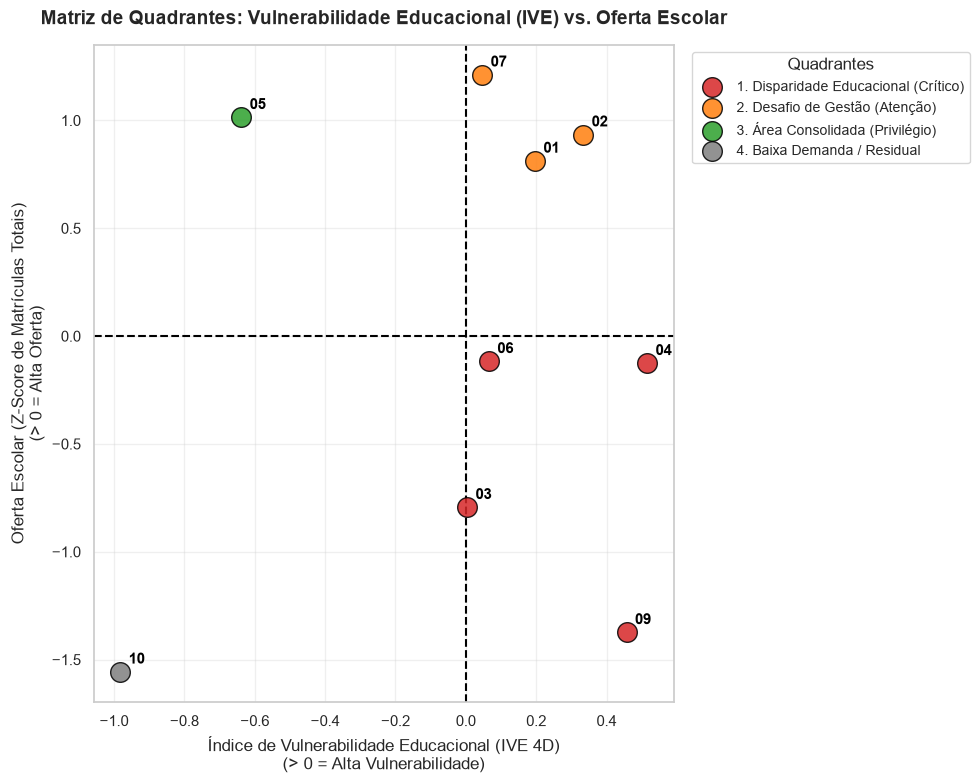

In [4]:
#Design gráfico
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_theme(style="whitegrid")
plt.figure(figsize=(10, 8))

# Cores
cores = {
    '1. Disparidade Educacional (Crítico)': '#D62728',      # Vermelho
    '2. Desafio de Gestão (Atenção)': '#FF7F0E',        # Laranja
    '3. Área Consolidada (Privilégio)': '#2CA02C',      # Verde
    '4. Baixa Demanda / Residual': '#7F7F7F'            # Cinza
}
# Scatter plot
for quadrante, cor in cores.items():
    subset = df_merged[df_merged['QUADRANTE'] == quadrante]
    plt.scatter(subset['IVE_FINAL_4D'], subset['Z_OFERTA'], 
                c=cor, s=200, label=quadrante, edgecolor='black', alpha=0.85, zorder=3)
    
    # Adicionar rótulo (código da AP, ex: '09') em cada ponto
    for i, row in subset.iterrows():
    # Pega os 2 últimos dígitos do código da AP
        ap_label = row['cd_apond'][-2:] 
        plt.annotate(ap_label, 
                     (row['IVE_FINAL_4D'], row['Z_OFERTA']), 
                     xytext=(6, 6), textcoords='offset points', 
                     fontsize=11, fontweight='bold', color='black')
# Linhas divisórias dos quadrantes (Média = 0)
plt.axvline(0, color='black', linestyle='--', linewidth=1.5, zorder=2)
plt.axhline(0, color='black', linestyle='--', linewidth=1.5, zorder=2)
# Formatação do Gráfico
plt.title('Matriz de Quadrantes: Vulnerabilidade Educacional (IVE) vs. Oferta Escolar', 
          fontsize=14, fontweight='bold', pad=15)
plt.xlabel('Índice de Vulnerabilidade Educacional (IVE 4D)\n(> 0 = Alta Vulnerabilidade)', 
           fontsize=12)
plt.ylabel('Oferta Escolar (Z-Score de Matrículas Totais)\n(> 0 = Alta Oferta)', 
           fontsize=12)
plt.legend(title='Quadrantes', bbox_to_anchor=(1.02, 1), loc='upper left', fontsize=10)
plt.grid(True, alpha=0.3, zorder=1)
plt.tight_layout()
# Salvar a figura em alta resolução (600 DPI) para o artigo
caminho_figura = f"{caminho_base}\\Matriz_Quadrantes_IVE_Oferta2.png"
plt.savefig(caminho_figura, dpi=300, bbox_inches='tight')
print(f"Gráfico salvo em alta resolução: {caminho_figura}")
plt.show()

In [5]:
#Exportando para arquivo geoespacial
# Juntar a classificação de quadrantes
gdf_final_artigo = gdf_ive.merge(
    df_merged[['cd_apond', 'QUADRANTE', 'MAT_UND', 'QTD_ESCOLAS', 'CRECHE', 'PRE_ESC']], 
    on='cd_apond', how='left'
)
caminho_saida_final = f"{caminho_base}\\Timon_Apond_Analise_Final_Artigo.gpkg"
gdf_final_artigo.to_file(caminho_saida_final, driver='GPKG', encoding='utf-8')
print(f"GeoPackage final salvo: {caminho_saida_final}")

GeoPackage final salvo: C:\Users\Waxl_Sampaio\Documents\Artigo_previa\Escolas_Aponds\Timon_Apond_Analise_Final_Artigo.gpkg
